# Retail Sales Analysis and Time Series Forecasting

Dataset: [Kaggle - Store Sales - Time Series Forecasting](https://www.kaggle.com/competitions/store-sales-time-series-forecasting)

Goal: analyse daily sales of Favorita stores and forecast the **total daily sales** for the next 30 days using 3 models:
Holt-Winters, SARIMA and Random Forest.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

sns.set_style("whitegrid")
DATA = "../data"
RESULTS = "../results"
os.makedirs(RESULTS, exist_ok=True)

## 1. Load data
Load `train.csv` (parsing the date column) and look at its basic properties.

In [2]:
train = pd.read_csv(f"{DATA}/train.csv", parse_dates=["date"])
oil = pd.read_csv(f"{DATA}/oil.csv", parse_dates=["date"])
holidays = pd.read_csv(f"{DATA}/holidays_events.csv", parse_dates=["date"])

print("Shape:", train.shape)
train.head()

Shape: (3000888, 6)


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [3]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype         
---  ------       -----         
 0   id           int64         
 1   date         datetime64[ns]
 2   store_nbr    int64         
 3   family       object        
 4   sales        float64       
 5   onpromotion  int64         
dtypes: datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 137.4+ MB


In [4]:
print("Missing values:")
print(train.isnull().sum())
print("\nDuplicate rows:", train.duplicated().sum())

Missing values:


id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64



Duplicate rows: 0


In [5]:
holidays.head()

,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False


## 2. Cleaning
- Drop duplicate rows.
- Aggregate to **daily total sales** (sum over all stores and product families).
- Some dates are missing (e.g. Christmas, when stores are closed), so we reindex to a full daily range and interpolate.
- Merge oil price and interpolate its missing values (oil is not traded on weekends/holidays).

In [6]:
train = train.drop_duplicates()

daily = train.groupby("date").agg(sales=("sales", "sum"), onpromotion=("onpromotion", "sum"))

full_range = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
print("Missing dates:", len(full_range) - len(daily))
daily = daily.reindex(full_range).interpolate()
daily.index.name = "date"

oil = oil.set_index("date").reindex(full_range)
oil["dcoilwtico"] = oil["dcoilwtico"].interpolate().bfill()
daily["oil"] = oil["dcoilwtico"].values

print(daily.isnull().sum())
daily.head()

Missing dates: 4
sales          0
onpromotion    0
oil            0
dtype: int64


,sales,onpromotion,oil
date,,,
2013-01-01,2511.618999,0.0,93.140000
2013-01-02,496092.417944,0.0,93.140000
2013-01-03,361461.231124,0.0,92.970000
2013-01-04,354459.677093,0.0,93.120000
2013-01-05,477350.121229,0.0,93.146667


## 3. Exploratory Data Analysis
Each plot is saved as a PNG in the `results/` folder.

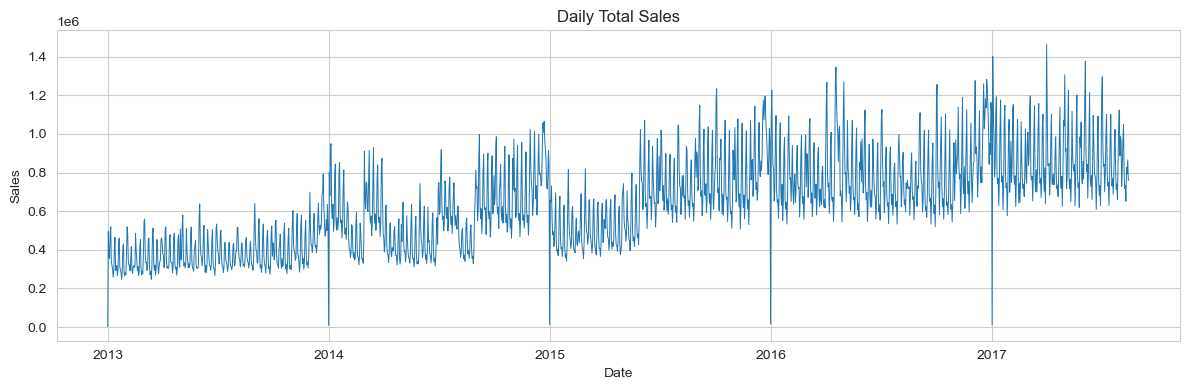

In [7]:
plt.figure(figsize=(12, 4))
plt.plot(daily.index, daily["sales"], linewidth=0.7)
plt.title("Daily Total Sales")
plt.xlabel("Date"); plt.ylabel("Sales")
plt.tight_layout(); plt.savefig(f"{RESULTS}/01_daily_sales.png"); plt.show()

Sales grow over time and show strong weekly ups and downs. Sales drop to almost zero on 1st January.

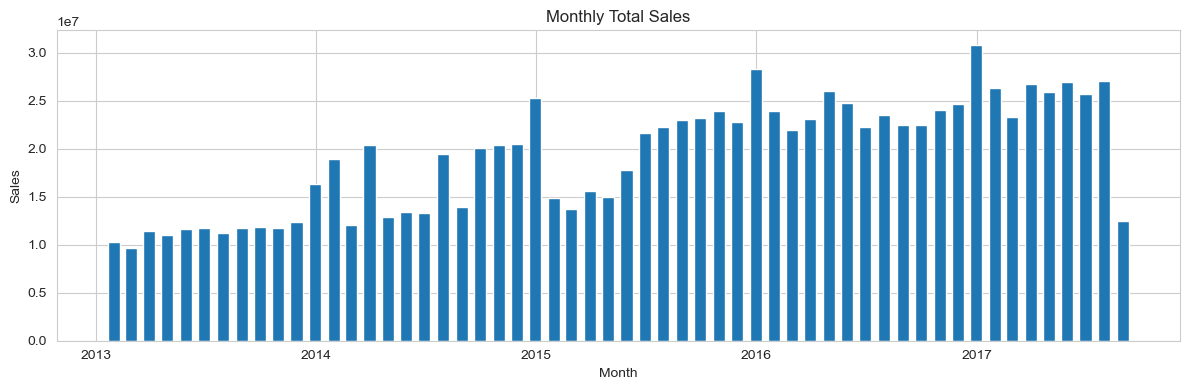

In [8]:
monthly = daily["sales"].resample("ME").sum()
plt.figure(figsize=(12, 4))
plt.bar(monthly.index, monthly.values, width=20)
plt.title("Monthly Total Sales")
plt.xlabel("Month"); plt.ylabel("Sales")
plt.tight_layout(); plt.savefig(f"{RESULTS}/02_monthly_sales.png"); plt.show()

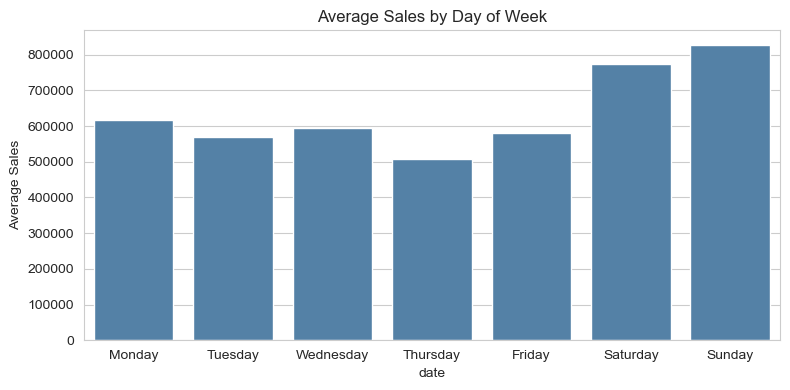

In [9]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
dow = daily.groupby(daily.index.day_name())["sales"].mean().reindex(days)
plt.figure(figsize=(8, 4))
sns.barplot(x=dow.index, y=dow.values, color="steelblue")
plt.title("Average Sales by Day of Week")
plt.ylabel("Average Sales")
plt.tight_layout(); plt.savefig(f"{RESULTS}/03_sales_by_weekday.png"); plt.show()

Weekends (Saturday and Sunday) have the highest sales.

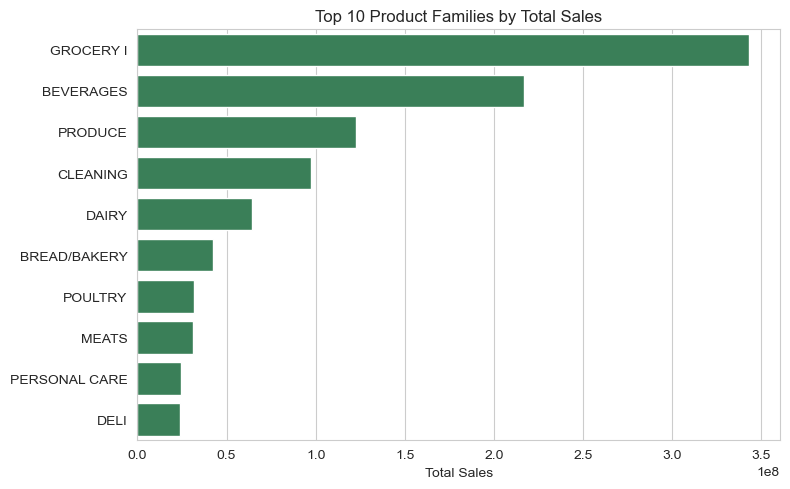

In [10]:
top_fam = train.groupby("family")["sales"].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(8, 5))
sns.barplot(x=top_fam.values, y=top_fam.index, color="seagreen")
plt.title("Top 10 Product Families by Total Sales")
plt.xlabel("Total Sales"); plt.ylabel("")
plt.tight_layout(); plt.savefig(f"{RESULTS}/04_top_families.png"); plt.show()

Grocery, beverages and produce make up most of the sales.

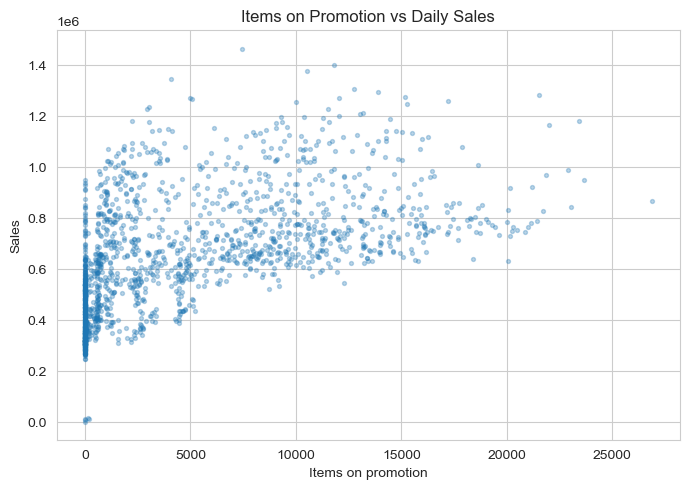

Correlation: 0.575


In [11]:
plt.figure(figsize=(7, 5))
plt.scatter(daily["onpromotion"], daily["sales"], alpha=0.3, s=8)
plt.title("Items on Promotion vs Daily Sales")
plt.xlabel("Items on promotion"); plt.ylabel("Sales")
plt.tight_layout(); plt.savefig(f"{RESULTS}/05_promotion_vs_sales.png"); plt.show()
print("Correlation:", round(daily["onpromotion"].corr(daily["sales"]), 3))

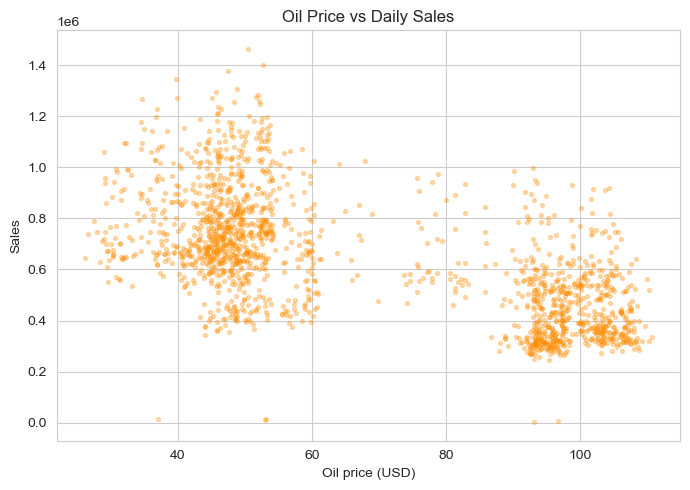

Correlation: -0.628


In [12]:
plt.figure(figsize=(7, 5))
plt.scatter(daily["oil"], daily["sales"], alpha=0.3, s=8, color="darkorange")
plt.title("Oil Price vs Daily Sales")
plt.xlabel("Oil price (USD)"); plt.ylabel("Sales")
plt.tight_layout(); plt.savefig(f"{RESULTS}/06_oil_vs_sales.png"); plt.show()
print("Correlation:", round(daily["oil"].corr(daily["sales"]), 3))

More promotions go with higher sales. Oil price has a negative correlation: Ecuador's economy depends on oil, and sales grew while oil prices fell after 2014.

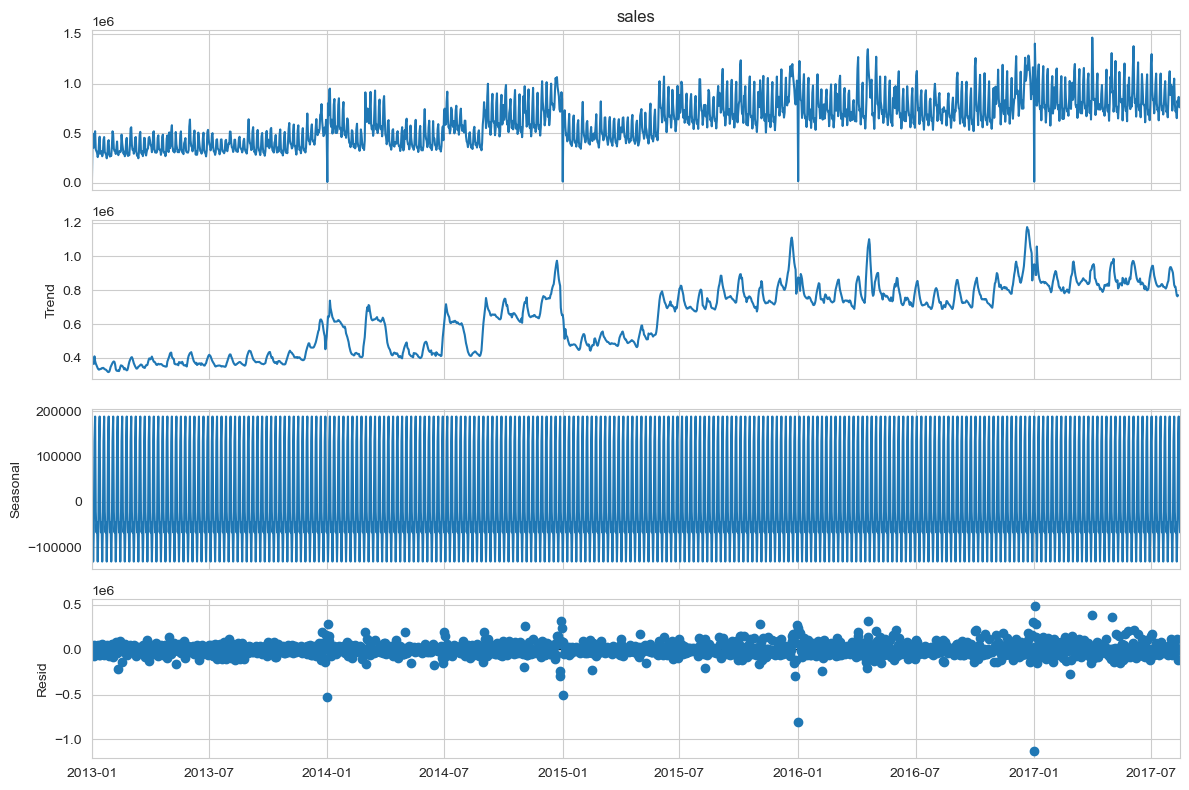

In [13]:
decomp = seasonal_decompose(daily["sales"], model="additive", period=7)
fig = decomp.plot()
fig.set_size_inches(12, 8)
plt.tight_layout(); plt.savefig(f"{RESULTS}/07_seasonal_decomposition.png"); plt.show()

The decomposition shows a rising **trend** and a clear **weekly seasonality** (period = 7).

## 4. Models
The **test set** is the last 30 days and the **train set** is everything before that.

In [14]:
series = daily["sales"]
train_s = series[:-30]
test_s = series[-30:]
print("Train:", train_s.index.min().date(), "to", train_s.index.max().date(), len(train_s), "days")
print("Test: ", test_s.index.min().date(), "to", test_s.index.max().date(), len(test_s), "days")
predictions = {}

Train: 2013-01-01 to 2017-07-16 1658 days
Test:  2017-07-17 to 2017-08-15 30 days


### Model 1: Holt-Winters Exponential Smoothing
Models level, trend and weekly seasonality (`seasonal_periods=7`).

In [15]:
hw = ExponentialSmoothing(train_s, trend="add", seasonal="add", seasonal_periods=7).fit()
predictions["Holt-Winters"] = hw.forecast(30).values

C:\Users\Hp\anaconda3\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(


### Model 2: SARIMA
Order (1,1,1) with seasonal order (1,1,1,7). To keep it fast, it is trained on the last 1 year only.

In [16]:
sarima = SARIMAX(train_s[-365:], order=(1, 1, 1), seasonal_order=(1, 1, 1, 7)).fit(disp=False)
predictions["SARIMA"] = sarima.forecast(30).values

### Model 3: Random Forest
Simple features: day of week, month, day of month, `lag_7` (sales 7 days ago) and `rolling_mean_7` (average of the previous 7 days).

Note: on the test set these features use the real past sales, so this is a one-step-ahead forecast. This gives the Random Forest a small advantage over the other two models, which forecast all 30 days at once.

In [17]:
df = daily[["sales"]].copy()
df["dayofweek"] = df.index.dayofweek
df["month"] = df.index.month
df["day"] = df.index.day
df["lag_7"] = df["sales"].shift(7)
df["rolling_mean_7"] = df["sales"].shift(1).rolling(7).mean()
df = df.dropna()

features = ["dayofweek", "month", "day", "lag_7", "rolling_mean_7"]
X_train, y_train = df[features][:-30], df["sales"][:-30]
X_test = df[features][-30:]

rf = RandomForestRegressor(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
predictions["Random Forest"] = rf.predict(X_test)

## 5. Evaluation
We compare the models with **MAE** (mean absolute error) and **RMSE** (root mean squared error). Lower is better.

In [18]:
rows = []
for name, pred in predictions.items():
    rows.append({"Model": name,
                 "MAE": mean_absolute_error(test_s, pred),
                 "RMSE": np.sqrt(mean_squared_error(test_s, pred))})
results = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
results.to_csv(f"{RESULTS}/model_comparison.csv", index=False)
results.round(0)

,Model,MAE,RMSE
0,Random Forest,54050.0,63279.0
1,Holt-Winters,56882.0,85673.0
2,SARIMA,60118.0,90266.0


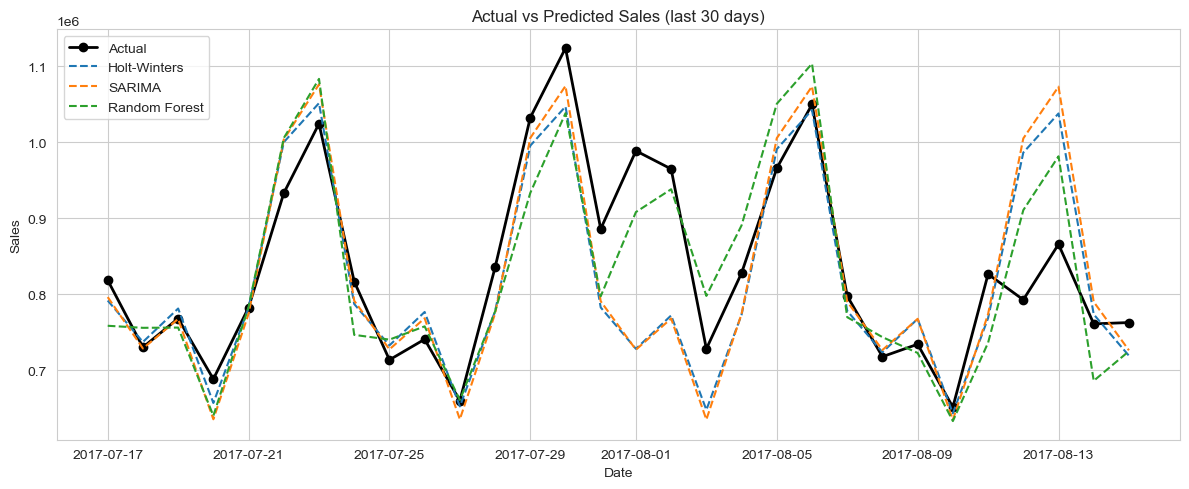

In [19]:
plt.figure(figsize=(12, 5))
plt.plot(test_s.index, test_s.values, "k-o", label="Actual", linewidth=2)
for name, pred in predictions.items():
    plt.plot(test_s.index, pred, "--", label=name)
plt.title("Actual vs Predicted Sales (last 30 days)")
plt.xlabel("Date"); plt.ylabel("Sales")
plt.legend()
plt.tight_layout(); plt.savefig(f"{RESULTS}/08_actual_vs_predictions.png"); plt.show()

In [20]:
best = results.iloc[0]
print(f"Best model: {best['Model']} (MAE = {best['MAE']:,.0f}, RMSE = {best['RMSE']:,.0f})")

Best model: Random Forest (MAE = 54,050, RMSE = 63,279)


## Conclusion
- Sales have a rising trend and a strong weekly pattern, with weekends being the busiest days.
- Promotions are positively related to sales (corr ~0.58); oil price is negatively related (corr ~-0.63).
- **Random Forest is the best model** (MAE ~54,000, RMSE ~63,000), partly because it uses the most recent actual sales through its lag and rolling-mean features.
- Of the two classical models, **Holt-Winters** (RMSE ~86,000) did slightly better than **SARIMA** (RMSE ~90,000).
- Possible improvements: add holiday and oil features, tune model parameters, and forecast per store/family.